# Walk-forward validation demo
Toy version of `docs/project-update/validation/walk-forward-validation.md`: logistic regression, two hyperparameters (`C`, `l1_ratio`), a few simple ratio features. Not the real feature pipeline.

Round t: train window FY2007..FY(t-1), test FY(t). Inside the window: train FY2007..FY(t-2), validation FY(t-1).
Bootstrap is left out (to discuss).

In [1]:
import warnings
import numpy as np
import pandas as pd
from itertools import product
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, roc_auc_score
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")   # saga convergence and BLAS matmul noise
raw = pd.read_csv("../../data/train-2025.csv", low_memory=False)

/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


## Data: label and features

In [2]:
def make_label(df, publish_month=5, horizon_months=12):
    # same as notebooks/02_labels.ipynb: 12-month default after the report is published
    pub = pd.to_datetime((df["fs_year"] + 1).astype(str) + f"-{publish_month:02d}-01") + pd.offsets.MonthEnd(0)
    end = pub + pd.DateOffset(months=horizon_months)
    dfl = pd.to_datetime(df["def_date"])
    keep = (dfl.isna() | (dfl > pub)) & (end <= dfl.max())
    return df[keep].assign(label=((dfl > pub) & (dfl <= end))[keep].astype(int))

FEATURES = ["equity_ratio", "profit_ratio", "ebitda_ratio", "cash_ratio", "bank_st_ratio", "wc_ratio", "log_assets"]

def make_features(df):
    a = df["asst_tot"].where(df["asst_tot"] > 0)
    f = pd.DataFrame({
        "equity_ratio": df["eqty_tot"] / a,
        "profit_ratio": df["profit"] / a,
        "ebitda_ratio": df["ebitda"] / a,
        "cash_ratio": df["cash_and_equiv"] / a,
        "bank_st_ratio": df["debt_bank_st"] / a,
        "wc_ratio": df["wc_net"] / a,
        "log_assets": np.log(a),
    }, index=df.index)
    return f.clip(-10, 10)   # crude outlier control, enough for a demo

# "new company" = no statement in any earlier year (computed before dropping unlabelled rows)
first_year = raw.groupby("id")["fs_year"].transform("min")

df = make_label(raw)
df = pd.concat([df, make_features(df)], axis=1)
df["is_new"] = df["fs_year"] == first_year.loc[df.index]
T = 0.015   # assumed known true population default rate (demo value, not estimated from the data)
print(df.groupby("fs_year")["label"].agg(["size", "mean"]), f"\nT = {T:.4f} (assumed)")

           size      mean
fs_year                  
2007     144251  0.008735
2008     161383  0.012052
2009     170549  0.015755
2010     174674  0.016494
2011     184159  0.013917 
T = 0.0150 (assumed)


## Steps
1. **Tune** (training dataset only): every `(C, l1_ratio)` runs on every expanding-window fold; imputer and scaler are fitted inside the fold; pick the highest mean AUC (ranking power comes first, the PD level is fixed by calibration).
2. **Refit** on the training dataset.
3. **Calibrate** on the validation year: quantile buckets -> default rate curve -> prior-shift from S to T.
4. **Test** once on FY(t).

In [3]:
GRID = list(product([0.001, 0.01, 0.1, 1.0], [0.0, 0.5, 1.0]))   # C, l1_ratio

def build(C, l1):
    return make_pipeline(
        SimpleImputer(strategy="median"), StandardScaler(),
        LogisticRegression(penalty="elasticnet", C=C, l1_ratio=l1, solver="saga", max_iter=200, tol=1e-3),
    )

def score(m, d):
    return m.predict_proba(d[FEATURES])[:, 1]

def tune(tune_df):
    # select by mean AUC (ranking power); calibration handles the PD level later. log-loss is only reported.
    years = sorted(tune_df["fs_year"].unique())
    rows = []
    for C, l1 in GRID:
        aucs, losses = [], []
        for v in years[1:]:                      # train years[:i] -> validate years[i]
            tr, va = tune_df[tune_df["fs_year"] < v], tune_df[tune_df["fs_year"] == v]
            m = build(C, l1).fit(tr[FEATURES], tr["label"])
            p = score(m, va)
            aucs.append(roc_auc_score(va["label"], p))
            losses.append(log_loss(va["label"], p))
        rows.append({"C": C, "l1_ratio": l1, "auc": np.mean(aucs), "logloss": np.mean(losses)})
    cv = pd.DataFrame(rows).sort_values("auc", ascending=False)
    best = cv.iloc[0]
    return (best["C"], best["l1_ratio"]), cv

def fit_calibrator(p_val, y_val, k=20):
    # k equal-size buckets by score (first = lowest score), curve: bucket mean score -> bucket default rate
    b = pd.qcut(pd.Series(p_val).rank(method="first"), k, labels=False)
    g = pd.DataFrame({"p": p_val, "y": y_val.values, "b": b.values}).groupby("b").mean()
    S = y_val.mean()
    def calibrate(p):
        pi = np.interp(p, g["p"], g["y"])        # model output -> PD in the validation sample
        return (T * pi - pi * S * T) / (pi * T - pi * S + S - S * T)   # prior shift S -> T
    return calibrate

In [4]:
def run_round(t):
    train = df[df["fs_year"] <= t - 2]
    val = df[df["fs_year"] == t - 1]
    test = df[df["fs_year"] == t].copy()

    (C, l1), cv = tune(train)
    model = build(C, l1).fit(train[FEATURES], train["label"])
    calibrate = fit_calibrator(score(model, val), val["label"])

    test["pd"] = calibrate(score(model, test))
    cvs[t] = cv
    return {
        "test_year": t, "C": C, "l1_ratio": l1, "cv_auc": cv["auc"].iloc[0], "cv_logloss": cv["logloss"].iloc[0],
        "auc_all": roc_auc_score(test["label"], test["pd"]),
        "auc_existing": roc_auc_score(test.loc[~test.is_new, "label"], test.loc[~test.is_new, "pd"]),
        "auc_new": roc_auc_score(test.loc[test.is_new, "label"], test.loc[test.is_new, "pd"]),
        "mean_pd": test["pd"].mean(), "observed": test["label"].mean(),
    }, test

results, tests, cvs = [], {}, {}
for t in [2010, 2011]:        # FY2007-2011 are labelled; t=2010 is the earliest round with >=2 training years
    r, tests[t] = run_round(t)
    results.append(r)
summary = pd.DataFrame(results).set_index("test_year")
summary["bias"] = summary["mean_pd"] - summary["observed"]
summary.round(4)

,C,l1_ratio,cv_auc,cv_logloss,auc_all,auc_existing,auc_new,mean_pd,observed,bias
test_year,,,,,,,,,,
2010,0.001,0.5,0.7903,0.0608,0.7768,0.7876,0.6511,0.0115,0.0165,-0.0050
2011,0.001,0.5,0.7887,0.0672,0.7995,0.8087,0.6858,0.0125,0.0139,-0.0014


In [5]:
for t, cv in cvs.items():
    print(f"FY{t} tuning grid (sorted by mean AUC)")
    print(cv.round(4).to_string(index=False), "\n")

FY2010 tuning grid (sorted by mean AUC)
    C  l1_ratio    auc  logloss
0.001       0.5 0.7903   0.0608
0.001       0.0 0.7891   0.0597
0.010       1.0 0.7883   0.0601
0.010       0.5 0.7859   0.0600
0.010       0.0 0.7824   0.0600
0.100       1.0 0.7817   0.0601
0.100       0.5 0.7812   0.0601
0.100       0.0 0.7807   0.0601
1.000       1.0 0.7806   0.0601
1.000       0.5 0.7805   0.0601
1.000       0.0 0.7805   0.0601
0.001       1.0 0.7631   0.0625 

FY2011 tuning grid (sorted by mean AUC)
    C  l1_ratio    auc  logloss
0.001       0.5 0.7887   0.0672
0.010       1.0 0.7840   0.0665
0.001       0.0 0.7839   0.0664
0.010       0.5 0.7821   0.0665
0.010       0.0 0.7792   0.0665
0.100       1.0 0.7788   0.0665
0.100       0.5 0.7785   0.0665
0.100       0.0 0.7781   0.0665
1.000       1.0 0.7780   0.0665
1.000       0.5 0.7780   0.0665
1.000       0.0 0.7779   0.0665
0.001       1.0 0.7770   0.0685 



Calibration plot per test year (deciles of calibrated PD vs observed default rate).

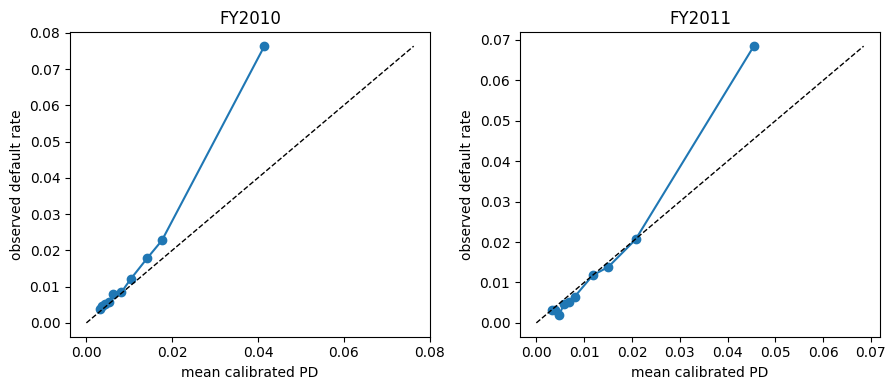

In [6]:
fig, axes = plt.subplots(1, len(tests), figsize=(9, 4))
for ax, (t, d) in zip(np.atleast_1d(axes), tests.items()):
    g = d.groupby(pd.qcut(d["pd"].rank(method="first"), 10, labels=False))[["pd", "label"]].mean()
    ax.plot(g["pd"], g["label"], "o-")
    m = g.max().max()
    ax.plot([0, m], [0, m], "k--", lw=1)
    ax.set(title=f"FY{t}", xlabel="mean calibrated PD", ylabel="observed default rate")
plt.tight_layout()

Not shown: the final model (same procedure, latest year kept for calibration) and the gap for label maturity.
Rounds are only t=2010, 2011: FY2012 has no usable labels, and t=2010 is the earliest round with two training years (so at least one tuning fold).